> [!info]- Служебная ячейка: макросы ролей для Jupyter
>
> В хранилище Obsidian макросы `\enfVar`, `\enfFun`, `\enfPar`, `\enfOp`, `\enfTgt` загружает `preamble.sty`, а цвет приходит из `css/enf-tokens.css`. У тетради Jupyter внешней преамбулы нет, поэтому макросы объявлены здесь один раз. Цвета — копия светлой темы из `css/enf-tokens.css` (версия палитры 1.0.0); вручную не править. Ячейку нужно отобразить до остальных: MathJax сохраняет объявления на время сессии.
>
> $$
\newcommand{\enfVar}[1]{{\color{#1D5B85}{#1}}}
\newcommand{\enfFun}[1]{{\color{#8A5214}{#1}}}
\newcommand{\enfPar}[1]{{\color{#3E7D3A}{#1}}}
\newcommand{\enfOp}[1]{{\color{#A32EAD}{#1}}}
\newcommand{\enfTgt}[1]{{\color{#7A0A2C}{#1}}}
$$

# Обработка тестов креативности: показатели Торренса

## Зачем это нужно

Тест креативности выглядит просто: испытуемый называет способы использования кирпича, психолог считает ответы. На деле за каждым числом стоит решение: какой ответ считать адекватным, к какой категории отнести идею, с какой выборкой сравнивать редкость. В лекции «Интеллектуальные способности, познавательная мотивация и творческие способности» (слайды 31, 32, 34) три утверждения о показателях Торренса были сделаны словами:

1. гибкость различает испытуемых лучше беглости;
2. оригинальность зависит от нормативной выборки;
3. беглость и оригинальность связаны механически.

В этом уроке все три проверяются на данных. Сначала — ручной расчёт для испытуемых А и Б из практикума лекции, затем тот же расчёт в коде, затем два эксперимента, которые руками уже не сделать. Ученик, знающий Python на уровне циклов и словарей, пройдёт урок за 90 минут.

> [!warning] Данные учебные
> Протоколы десяти испытуемых составлены для урока, выборка из 200 человек порождена генератором случайных чисел. Пороги оригинальности $\enfPar{\tau_1}$ и $\enfPar{\tau_2}$ — учебная договорённость. Числа урока нельзя использовать как нормы.

## Обозначения

| Символ | Значение | Роль |
|--------|----------|------|
| $\enfVar{S_i}$ | множество адекватных неповторяющихся ответов испытуемого $i$ | `variable` |
| $\enfVar{s}$ | отдельный ответ (идея) | `variable` |
| $\enfVar{d_s}$ | число деталей, которыми дополнен ответ $\enfVar{s}$ | `variable` |
| $\enfFun{c}$ | правило категоризации: ответ → категория | `function` |
| $\enfOp{n}$ | подсчёт: сколько испытуемых выборки дали ответ | `operator` |
| $\enfPar{N}$ | объём нормативной выборки | `parameter` |
| $\enfFun{p}$ | доля выборки, давшая ответ | `function` |
| $\enfFun{w}$ | балл оригинальности отдельного ответа | `function` |
| $\enfPar{\tau_1}$, $\enfPar{\tau_2}$ | пороги редкости: $\enfPar{0{,}10}$ и $\enfPar{0{,}30}$ | `parameter` |
| $\enfOp{\sum}$ | суммирование по ответам испытуемого | `operator` |
| $\enfTgt{F_i}$ | беглость | `target` |
| $\enfTgt{G_i}$ | гибкость | `target` |
| $\enfTgt{O_i}$ | оригинальность | `target` |
| $\enfTgt{\bar O_i}$ | оригинальность в расчёте на один ответ | `target` |
| $\enfTgt{E_i}$ | разработанность | `target` |
| $\enfOp{\operatorname{corr}}$ | коэффициент корреляции Пирсона | `operator` |
| $\enfPar{\mu_F}$, $\enfPar{\sigma_F}$ | среднее и стандартное отклонение беглости в выборке | `parameter` |
| $\enfTgt{T_i}$ | T-балл беглости: шкала со средним $\enfPar{50}$ и отклонением $\enfPar{10}$ | `target` |

Индекс $i$ — номер испытуемого — нейтрален. Переменная суммирования под $\enfOp{\sum}$ тоже нейтральна.

## Показатели и ручной расчёт

Ответы испытуемого сначала очищаются: неадекватные ответы и повторы удаляются, остаётся множество $\enfVar{S_i}$. Беглость — его размер:

$$
\enfTgt{F_i} = \lvert \enfVar{S_i} \rvert .
$$

Гибкость — число разных категорий среди ответов:

$$
\enfTgt{G_i} = \bigl\lvert \{\, \enfFun{c}(\enfVar{s}) : \enfVar{s} \in \enfVar{S_i} \,\} \bigr\rvert .
$$

Оригинальность считается по редкости ответа в выборке. Доля испытуемых, давших ответ:

$$
\enfFun{p}(\enfVar{s}) = \frac{\enfOp{n}(\enfVar{s})}{\enfPar{N}} ,
$$

балл ответа по учебному правилу:

$$
\enfFun{w}(\enfVar{s}) =
\begin{cases}
2, & \enfFun{p}(\enfVar{s}) \le \enfPar{\tau_1},\\
1, & \enfPar{\tau_1} < \enfFun{p}(\enfVar{s}) \le \enfPar{\tau_2},\\
0, & \enfFun{p}(\enfVar{s}) > \enfPar{\tau_2},
\end{cases}
$$

оригинальность испытуемого и её вариант в расчёте на ответ:

$$
\enfTgt{O_i} = \enfOp{\sum_{s \in S_i}} \enfFun{w}(\enfVar{s}) ,
\qquad
\enfTgt{\bar O_i} = \frac{\enfTgt{O_i}}{\enfTgt{F_i}} .
$$

Разработанность — сумма деталей по ответам:

$$
\enfTgt{E_i} = \enfOp{\sum_{s \in S_i}} \enfVar{d_s} .
$$

### Ручной расчёт для испытуемых А и Б

Учебная выборка — $\enfPar{N} = 10$ испытуемых, в неё входят А и Б из практикума лекции.

**Шаг 1. Беглость.** Ответы А и Б адекватны и не повторяются, поэтому $\enfTgt{F_А} = 8$, $\enfTgt{F_Б} = 6$.

**Шаг 2. Гибкость.** Все ответы А относятся к категории «строительство»: $\enfTgt{G_А} = 1$. Ответы Б попадают в шесть разных категорий: $\enfTgt{G_Б} = 6$.

**Шаг 3. Доли и баллы.** Подсчёт по десяти протоколам даёт для ответов А: «дом» $\enfOp{n} = \enfOp{9}$, «забор» и «стена» по $\enfOp{4}$, «печь» $\enfOp{3}$, «гараж», «сарай», «камин» по $\enfOp{2}$, «дорожка» $\enfOp{1}$. Для ответов Б: «подпереть дверь» $\enfOp{3}$, «разбить окно» и «гнёт» по $\enfOp{2}$, «грелка», «пигмент», «груз для тренировки» по $\enfOp{1}$. Доля $\enfFun{p}(\enfVar{s}) = \enfOp{n}(\enfVar{s})/\enfPar{10}$; доля $\enfFun{0{,}1}$ не превышает $\enfPar{\tau_1} = \enfPar{0{,}10}$ и даёт 2 балла, доли $\enfFun{0{,}2}$ и $\enfFun{0{,}3}$ не превышают $\enfPar{\tau_2} = \enfPar{0{,}30}$ и дают 1 балл, доли $\enfFun{0{,}4}$ и $\enfFun{0{,}9}$ дают 0.

**Шаг 4. Оригинальность.** Складываем баллы по ответам: $\enfTgt{O_А} = 0+1+0+1+0+1+2+1 = 6$ и $\enfTgt{O_Б} = 1+1+1+2+2+2 = 9$. В расчёте на ответ $\enfTgt{\bar O_А} = 6/8 = 0{,}75$ и $\enfTgt{\bar O_Б} = 9/6 = 1{,}5$.

**Шаг 5. Разработанность.** Эксперт отметил по одной детали в двух ответах Б («разбить окно, если ключи остались внутри», «грелка зимой»): $\enfTgt{E_Б} = 1 + 1 = 2$, $\enfTgt{E_А} = 0$.

Эти числа код должен воспроизвести.

## От формулы к коду

| Символ | Смысл | В коде | Тип и форма |
|--------|-------|--------|-------------|
| $\enfFun{c}$ | правило категоризации | `category` | `dict[str, str]`: ответ → категория |
| — | сырой протокол | `protocols[i]` | `list[tuple[str, int]]`: пары (ответ, детали) |
| $\enfVar{S_i}$ | очищенные ответы | `S[i]` | `dict[str, int]`: ответ → $\enfVar{d_s}$ |
| $\enfTgt{F_i}$, $\enfTgt{G_i}$, $\enfTgt{E_i}$ | беглость, гибкость, разработанность | `F[i]`, `G[i]`, `E[i]` | `int` |
| $\enfPar{N}$ | объём выборки | `N` | `int` |
| $\enfOp{n}(\enfVar{s})$ | число испытуемых с ответом | `n[s]` | `dict[str, int]` |
| $\enfFun{p}(\enfVar{s})$ | доля выборки | `p[s]` | `dict[str, float]` |
| $\enfFun{w}$, $\enfPar{\tau_1}$, $\enfPar{\tau_2}$ | правило баллов и пороги | `w(p_s, tau1, tau2)` | функция → `int` |
| $\enfTgt{O_i}$, $\enfTgt{\bar O_i}$ | оригинальность | `O[i]`, `O_bar[i]` | `int`, `float` |

Множество $\enfVar{S_i}$ хранится словарём, а не множеством `set`: ключи словаря уникальны, как элементы множества, а значение при ключе хранит число деталей $\enfVar{d_s}$, нужное для разработанности.

## Реализация

### Шаг 1. Окружение

Подключаем библиотеки и создаём один генератор случайных чисел: он понадобится только в шаге 8, но объявляется в начале, чтобы результат урока был воспроизводим.

In [1]:
import numpy as np                                  # (1)
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)                     # (2)
print(f"numpy {np.__version__}, pandas {pd.__version__}")

numpy 2.4.4, pandas 3.0.2


**Разбор.**

**(1)** `import ... as np` подключает библиотеку под коротким именем: дальше пишем `np.array`, а не `numpy.array`.

**(2)** Генератор с зерном `42` (поле `code_seed` фронтматтера) выдаёт одну и ту же последовательность случайных чисел при каждом запуске. Любой дополнительный вызов `rng` выше шага 8 изменил бы выборку шага 8.

### Шаг 2. Правило категоризации $\enfFun{c}$

Категоризацию делает эксперт; в коде её результат — словарь «ответ → категория». Ответ, которого в словаре нет, считаем неадекватным заданию.

In [2]:
category: dict[str, str] = {                        # (1)
    "дом": "строительство", "гараж": "строительство",
    "забор": "строительство", "печь": "строительство",
    "стена": "строительство", "сарай": "строительство",
    "дорожка": "строительство", "камин": "строительство",
    "подпереть дверь": "опора", "подставка": "опора",
    "разбить окно": "разрушение",
    "гнёт": "груз в быту", "пресс-папье": "груз в быту",
    "грелка": "тепло", "пигмент": "сырьё",
    "груз для тренировки": "спорт",
    "забить гвоздь": "инструмент",
}
n_cat = len(set(category.values()))                 # (2)
print(len(category), "допустимых ответов,", n_cat, "категорий")

17 допустимых ответов, 8 категорий


**Разбор.**

**(1)** Словарь `dict[str, str]` — это и есть функция $\enfFun{c}$, заданная таблицей: `category["гнёт"]` возвращает `"груз в быту"`. Аннотация типа после двоеточия подсказывает читателю, что лежит в словаре, и не влияет на выполнение.

**(2)** `category.values()` — все категории с повторами; `set(...)` убирает повторы; `len` считает оставшиеся.

### Шаг 3. Протоколы испытуемых

Каждый протокол — список пар «(ответ, число деталей $\enfVar{d_s}$)». Протокол Д содержит неадекватный ответ «съесть» и повтор «дом»: очистка в шаге 4 должна их убрать.

In [3]:
protocols: dict[str, list[tuple[str, int]]] = {     # (1)
    "А": [("дом", 0), ("гараж", 0), ("забор", 0), ("печь", 0),
          ("стена", 0), ("сарай", 0), ("дорожка", 0), ("камин", 0)],
    "Б": [("подпереть дверь", 0), ("разбить окно", 1), ("гнёт", 0),
          ("грелка", 1), ("пигмент", 0), ("груз для тренировки", 0)],
    "В": [("дом", 0), ("забор", 0), ("забить гвоздь", 1),
          ("подпереть дверь", 0)],
    "Г": [("дом", 0), ("стена", 0), ("печь", 1), ("пресс-папье", 0)],
    "Д": [("дом", 0), ("гараж", 0), ("забить гвоздь", 0),
          ("съесть", 0), ("дом", 1)],                # (2)
    "Е": [("дом", 0), ("забор", 0), ("подставка", 1),
          ("пресс-папье", 0), ("забить гвоздь", 0)],
    "Ж": [("дом", 0), ("сарай", 0), ("стена", 0)],
    "З": [("дом", 0), ("забить гвоздь", 0), ("подпереть дверь", 0),
          ("разбить окно", 0)],
    "И": [("печь", 0), ("камин", 1), ("дом", 0), ("подставка", 0)],
    "К": [("дом", 0), ("забор", 0), ("стена", 0), ("гнёт", 0)],
}
print("испытуемых:", len(protocols))

испытуемых: 10


**Разбор.**

**(1)** Ключ словаря — обозначение испытуемого, значение — список кортежей. Кортеж `("дом", 0)` неизменяем: пару «ответ — детали» нельзя случайно испортить при обработке.

**(2)** Повтор «дом» записан с одной деталью: испытуемый вернулся к идее и уточнил её. При очистке останется один ответ «дом», а детали возьмём по максимуму — так уточнение не потеряется.

### Шаг 4. Очистка и беглость $\enfTgt{F_i} = \lvert \enfVar{S_i} \rvert$

Функция строит множество $\enfVar{S_i}$ по сырому протоколу, после чего беглость — просто размер множества.

In [4]:
def adequate_set(answers: list[tuple[str, int]]) -> dict[str, int]:
    """Множество S_i: адекватные ответы без повторов -> d_s."""
    S_i: dict[str, int] = {}
    for s, d in answers:                            # (1)
        if s not in category:                       # (2)
            continue
        S_i[s] = max(S_i.get(s, 0), d)              # (3)
    return S_i


S = {i: adequate_set(a) for i, a in protocols.items()}
F = {i: len(S_i) for i, S_i in S.items()}           # (4)
print("S_Д:", S["Д"])
print("F:", F)

S_Д: {'дом': 1, 'гараж': 0, 'забить гвоздь': 0}
F: {'А': 8, 'Б': 6, 'В': 4, 'Г': 4, 'Д': 3, 'Е': 5, 'Ж': 3, 'З': 4, 'И': 4, 'К': 4}


**Таблица 1. Беглость: формула → код.**

| Формула | Python |
|---|---|
| $\enfVar{s}$ | `for s, d in answers` — перебор ответов протокола вместе с числом деталей |
| условие адекватности | `if s not in category: continue` — ответ вне словаря $\enfFun{c}$ в $\enfVar{S_i}$ не попадает |
| отсутствие повторов в $\enfVar{S_i}$ | `S_i[s] = ...` — ключ словаря уникален, повтор перезаписывает ту же запись |
| $\lvert \enfVar{S_i} \rvert$ | `len(S_i)` — число ключей словаря, то есть элементов множества |
| вся формула: $\enfTgt{F_i} = \lvert \enfVar{S_i} \rvert$ | `F = {i: len(S_i) for i, S_i in S.items()}` |

**Разбор.**

**(1)** Распаковка: каждый кортеж `("дом", 0)` раскладывается в две переменные — `s` получает ответ, `d` — детали.

**(2)** `continue` прерывает текущий шаг цикла и переходит к следующему ответу: «съесть» дальше не обрабатывается.

**(3)** `S_i.get(s, 0)` возвращает уже записанные детали или `0`, если ответа ещё нет; `max` сохраняет большее. Поэтому у Д «дом» записан с одной деталью.

**(4)** Словарное включение `{ключ: значение for ...}` строит словарь в одну строку; здесь — беглость каждого испытуемого.

Сверка с ручным расчётом: $\enfTgt{F_А} = 8$ и $\enfTgt{F_Б} = 6$ совпали. У Д из пяти записей осталось три ответа — неадекватный и повтор удалены.

### Шаг 5. Гибкость $\enfTgt{G_i}$

Гибкость — число разных категорий $\enfFun{c}(\enfVar{s})$ среди ответов испытуемого.

In [5]:
G = {i: len({category[s] for s in S_i})            # (1)
     for i, S_i in S.items()}
print("категории А:", {category[s] for s in S["А"]})
print("G:", G)

категории А: {'строительство'}
G: {'А': 1, 'Б': 6, 'В': 3, 'Г': 2, 'Д': 2, 'Е': 4, 'Ж': 1, 'З': 4, 'И': 2, 'К': 2}


**Таблица 2. Гибкость: формула → код.**

| Формула | Python |
|---|---|
| $\enfVar{s} \in \enfVar{S_i}$ | `for s in S_i` — перебор ключей словаря, то есть очищенных ответов |
| $\enfFun{c}(\enfVar{s})$ | `category[s]` — категория ответа по экспертному словарю |
| $\{\ldots\}$ | `{... for s in S_i}` — множество: одинаковые категории схлопываются в одну |
| $\lvert \ldots \rvert$ | `len(...)` — размер множества категорий |
| вся формула: $\enfTgt{G_i} = \bigl\lvert \{\enfFun{c}(\enfVar{s}) : \enfVar{s} \in \enfVar{S_i}\} \bigr\rvert$ | `len({category[s] for s in S_i})` |

**Разбор.**

**(1)** Внутренние фигурные скобки без двоеточия строят не словарь, а множество `set`. Восемь ответов А дают восемь раз «строительство», а множество хранит его один раз — отсюда $\enfTgt{G_А} = 1$.

Сверка: $\enfTgt{G_А} = 1$, $\enfTgt{G_Б} = 6$, как в ручном расчёте. Гибкость разводит А и Б в шесть раз, тогда как беглость — лишь в $\enfTgt{8}/\enfTgt{6} \approx 1{,}33$ раза и в обратную сторону.

### Шаг 6. Доли $\enfFun{p}(\enfVar{s})$ и баллы $\enfFun{w}(\enfVar{s})$

Считаем, сколько испытуемых дали каждый ответ, переводим в долю от $\enfPar{N}$ и назначаем балл по порогам $\enfPar{\tau_1}$, $\enfPar{\tau_2}$.

In [6]:
N = len(S)                                          # (1)
n: dict[str, int] = {}
for S_i in S.values():                              # (2)
    for s in S_i:
        n[s] = n.get(s, 0) + 1
p = {s: n_s / N for s, n_s in n.items()}            # (3)


def w(p_s: float, tau1: float = 0.10, tau2: float = 0.30) -> int:
    """Балл оригинальности ответа по его доле в выборке."""
    if p_s <= tau1:                                 # (4)
        return 2
    if p_s <= tau2:
        return 1
    return 0


for s in S["Б"]:
    print(f"{s:<20} n={n[s]}  p={p[s]:.1f}  w={w(p[s])}")

подпереть дверь      n=3  p=0.3  w=1
разбить окно         n=2  p=0.2  w=1
гнёт                 n=2  p=0.2  w=1
грелка               n=1  p=0.1  w=2
пигмент              n=1  p=0.1  w=2
груз для тренировки  n=1  p=0.1  w=2


**Таблица 3. Доля выборки: формула → код.**

| Формула | Python |
|---|---|
| $\enfPar{N}$ | `N = len(S)` — объём выборки равен числу протоколов |
| $\enfOp{n}(\enfVar{s})$ | `n[s] = n.get(s, 0) + 1` — прибавляем единицу за каждого испытуемого с этим ответом |
| считаем по испытуемым, а не по ответам | `for s in S_i` — перебираем очищенные $\enfVar{S_i}$, поэтому повтор у одного человека не удваивает счёт |
| деление на $\enfPar{N}$ | `n_s / N` — делим на число людей; деление на число всех ответов — типичная ошибка (см. ниже) |
| вся формула: $\enfFun{p}(\enfVar{s}) = \enfOp{n}(\enfVar{s})/\enfPar{N}$ | `p = {s: n_s / N for s, n_s in n.items()}` |

**Таблица 4. Балл оригинальности: формула → код.**

| Формула | Python |
|---|---|
| $\enfPar{\tau_1}$, $\enfPar{\tau_2}$ | `tau1: float = 0.10, tau2: float = 0.30` — значения по умолчанию, их можно менять при вызове |
| $\enfFun{p}(\enfVar{s}) \le \enfPar{\tau_1} \Rightarrow 2$ | `if p_s <= tau1: return 2` — граница включена в редкий класс |
| $\enfPar{\tau_1} < \enfFun{p}(\enfVar{s}) \le \enfPar{\tau_2} \Rightarrow 1$ | `if p_s <= tau2: return 1` — условие $> \enfPar{\tau_1}$ уже выполнено, раз первое `if` не сработало |
| $\enfFun{p}(\enfVar{s}) > \enfPar{\tau_2} \Rightarrow 0$ | `return 0` — все остальные случаи |
| вся формула: $\enfFun{w}(\enfVar{s})$ по трём случаям | `def w(p_s, tau1=0.10, tau2=0.30) -> int` |

**Разбор.**

**(1)** Объём выборки — число ключей словаря `S`.

**(2)** Двойной цикл: внешний перебирает испытуемых, внутренний — их ответы. `n.get(s, 0)` возвращает текущий счёт или ноль для нового ответа.

**(3)** Доля — частное счёта и объёма выборки. Сравнение `0.1 <= 0.10` здесь точное: `1/10` и литерал `0.10` дают одно и то же число с плавающей точкой.

**(4)** Проверки идут от самого редкого класса к частому; первая выполненная возвращает результат и завершает функцию.

Сверка с ручным расчётом: для ответов Б получены $\enfOp{n} = \enfOp{3}, \enfOp{2}, \enfOp{2}, \enfOp{1}, \enfOp{1}, \enfOp{1}$ и баллы $\enfFun{w} = \enfFun{1}, \enfFun{1}, \enfFun{1}, \enfFun{2}, \enfFun{2}, \enfFun{2}$.

### Шаг 7. Оригинальность $\enfTgt{O_i}$ и $\enfTgt{\bar O_i}$

Складываем баллы по ответам испытуемого и делим сумму на беглость.

In [7]:
O = {i: sum(w(p[s]) for s in S_i)                   # (1)
     for i, S_i in S.items()}
O_bar = {i: O[i] / F[i] for i in S}                 # (2)
for i in ("А", "Б"):
    print(i, " O =", O[i], "  O_bar =", round(O_bar[i], 2))

А  O = 6   O_bar = 0.75
Б  O = 9   O_bar = 1.5


**Таблица 5. Оригинальность: формула → код.**

| Формула | Python |
|---|---|
| $\enfVar{s} \in \enfVar{S_i}$ | `for s in S_i` — только очищенные ответы испытуемого |
| $\enfFun{w}(\enfVar{s})$ | `w(p[s])` — балл ответа по его доле в выборке |
| $\enfOp{\sum_{s \in S_i}}$ | `sum(... for s in S_i)` — сумма генераторного выражения |
| $\enfTgt{O_i}/\enfTgt{F_i}$ | `O[i] / F[i]` — деление на беглость; у испытуемого без ответов $\enfTgt{F_i} = 0$, и такой случай пришлось бы обработать отдельно |
| вся формула: $\enfTgt{O_i} = \enfOp{\sum_{s \in S_i}} \enfFun{w}(\enfVar{s})$ | `O = {i: sum(w(p[s]) for s in S_i) for i, S_i in S.items()}` |

**Разбор.**

**(1)** `sum(w(p[s]) for s in S_i)` — генераторное выражение внутри `sum`: баллы вычисляются по одному и сразу складываются, промежуточный список не создаётся.

**(2)** Деление целых в Python 3 даёт дробь: `6 / 8` равно `0.75`.

Трассировка суммы для А — порядок ответов как в протоколе:

In [8]:
total = 0
for s in S["А"]:                                    # (1)
    total += w(p[s])
    print(f"{s:<8} n={n[s]}  p={p[s]:.1f}  w={w(p[s])}  сумма={total}")

дом      n=9  p=0.9  w=0  сумма=0
гараж    n=2  p=0.2  w=1  сумма=1
забор    n=4  p=0.4  w=0  сумма=1
печь     n=3  p=0.3  w=1  сумма=2
стена    n=4  p=0.4  w=0  сумма=2
сарай    n=2  p=0.2  w=1  сумма=3
дорожка  n=1  p=0.1  w=2  сумма=5
камин    n=2  p=0.2  w=1  сумма=6


**Разбор.**

**(1)** Тот же расчёт, что в шаге 7, но с печатью накопленной суммы после каждого ответа. Оператор `+=` прибавляет балл к `total`.

Сверка: $\enfTgt{O_А} = 6$, $\enfTgt{O_Б} = 9$, $\enfTgt{\bar O_А} = 0{,}75$, $\enfTgt{\bar O_Б} = 1{,}5$ — как в ручном расчёте. Шесть баллов А — не редкость его идей, а их количество: половина суммы набрана ответами с баллом 1, которые встречаются у двух-трёх человек из десяти.

### Шаг 8. Разработанность $\enfTgt{E_i}$ и сводная таблица

Разработанность — сумма деталей $\enfVar{d_s}$, сохранённых в значениях словаря $\enfVar{S_i}$.

In [9]:
E = {i: sum(S_i.values()) for i, S_i in S.items()}  # (1)
summary = pd.DataFrame(                             # (2)
    {"F": F, "G": G, "O": O, "O_bar": O_bar, "E": E}
)
summary["O_bar"] = summary["O_bar"].round(2)
print(summary)

   F  G  O  O_bar  E
А  8  1  6   0.75  0
Б  6  6  9   1.50  2
В  4  3  1   0.25  1
Г  4  2  2   0.50  1
Д  3  2  1   0.33  1
Е  5  4  2   0.40  1
Ж  3  1  1   0.33  0
З  4  4  2   0.50  0
И  4  2  3   0.75  1
К  4  2  1   0.25  0


**Таблица 6. Разработанность: формула → код.**

| Формула | Python |
|---|---|
| $\enfVar{d_s}$ | значение `S_i[s]` — число деталей, записанное при очистке в шаге 4 |
| при повторе ответа берётся большее $\enfVar{d_s}$ | `max(S_i.get(s, 0), d)` в шаге 4 — уточнение не теряется |
| $\enfOp{\sum_{s \in S_i}}$ | `sum(S_i.values())` — сумма всех значений словаря |
| детали неадекватных ответов | не учитываются: ответ «съесть» не попал в `S_i` |
| вся формула: $\enfTgt{E_i} = \enfOp{\sum_{s \in S_i}} \enfVar{d_s}$ | `E = {i: sum(S_i.values()) for i, S_i in S.items()}` |

**Разбор.**

**(1)** `S_i.values()` — все значения словаря, то есть числа деталей по ответам.

**(2)** `pd.DataFrame` из словаря словарей: внешние ключи (`"F"`, `"G"`, …) становятся столбцами, внутренние ключи (`"А"`, `"Б"`, …) — строками.

Сверка: $\enfTgt{E_А} = 0$, $\enfTgt{E_Б} = 2$. В сводной таблице видно утверждение лекции: А лидирует по беглости и одновременно делит с Ж последнее место по гибкости.

### Шаг 9. Оригинальность зависит от нормативной выборки

Оценим тех же А и Б по другой выборке — десяти студентам художественного училища, для которых «пигмент» и «грелка» — частые ответы. Для этого обобщим подсчёт: функция `counts` строит $\enfOp{n}(\enfVar{s})$ для любой выборки, функция `originality` считает $\enfTgt{O_i}$ относительно заданных норм. Ответ, которого в нормативной выборке нет, получает $\enfOp{n}(\enfVar{s}) = 0$, то есть максимальный балл.

In [10]:
def counts(S_all: dict) -> dict[str, int]:
    """n(s): сколько испытуемых выборки дали ответ s."""
    n_all: dict[str, int] = {}
    for S_i in S_all.values():
        for s in S_i:
            n_all[s] = n_all.get(s, 0) + 1
    return n_all


def originality(S_i: dict, n_norm: dict, N_norm: int) -> int:
    """O_i относительно нормативной выборки объёма N_norm."""
    return sum(w(n_norm.get(s, 0) / N_norm) for s in S_i)  # (1)


n_check = counts(S)
print("совпадает с шагом 6:", n_check == n)

совпадает с шагом 6: True


**Разбор.**

**(1)** `n_norm.get(s, 0)` возвращает ноль для ответа, которого в нормах нет; доля получается нулевой, и `w` даёт 2 балла.

Проверка `n_check == n` подтверждает, что обобщённая функция `counts` на школьной выборке даёт ровно те же счёты, что двойной цикл шага 6.

Теперь нормативная выборка училища:

In [11]:
art = [["пигмент", "подставка", "дом"], ["пигмент", "грелка"],
       ["пигмент", "подпереть дверь", "пресс-папье"],
       ["пигмент", "грелка", "подставка"],
       ["пигмент", "подпереть дверь"], ["пигмент", "грелка", "дом"],
       ["подпереть дверь", "пресс-папье", "грелка"],
       ["подпереть дверь", "разбить окно"], ["дом", "подставка"],
       ["пресс-папье", "дом"]]
S_art = {f"х{k}": {s: 0 for s in a} for k, a in enumerate(art)}  # (1)
n_art = counts(S_art)
for i in ("А", "Б"):
    print(i, " школа:", originality(S[i], n, N),
          "  училище:", originality(S[i], n_art, len(S_art)))

А  школа: 6   училище: 14
Б  школа: 9   училище: 6


**Разбор.**

**(1)** Вложенное включение превращает список ответов в словарь с нулевыми деталями — ту же форму, что у `S[i]`, чтобы функции работали с обеими выборками одинаково.

Результат переворачивает вывод практикума: по школьной выборке Б оригинальнее А, по выборке училища — наоборот. Идеи А («гараж», «печь», «сарай») студенты училища не называли, а ответы Б «пигмент», «грелка», «подпереть дверь» для них обычны. Это и есть утверждение лекции: «оригинальный» значит «редкий в этой выборке».

### Шаг 10. Беглость и оригинальность связаны механически

На десяти протоколах связь не увидеть, поэтому порождаем учебную выборку из 200 испытуемых. Пул — 40 идей с убывающей популярностью: первая идея самая частая, сороковая — самая редкая. Каждый испытуемый называет $1 + \text{Poisson}(4)$ разных идей, но не больше 15, и выбирает их с вероятностями, пропорциональными популярности. Никакой «креативности» в генератор не заложено: все испытуемые берут идеи из одного распределения и отличаются только числом ответов.

In [12]:
ideas = [f"идея_{k:02d}" for k in range(1, 41)]
weights = 1 / np.arange(1, 41) ** 1.2               # (1)
weights = weights / weights.sum()
S_big: dict[int, dict[str, int]] = {}
for i in range(200):                                # (2)
    F_i = min(1 + int(rng.poisson(4)), 15)
    chosen = rng.choice(ideas, size=F_i, replace=False, p=weights)
    S_big[i] = {str(s): 0 for s in chosen}
n_big = counts(S_big)
F_big = np.array([len(S_i) for S_i in S_big.values()])
O_big = np.array([originality(S_i, n_big, len(S_big))
                  for S_i in S_big.values()])
O_bar_big = O_big / F_big
r_FO = np.corrcoef(F_big, O_big)[0, 1]              # (3)
r_FObar = np.corrcoef(F_big, O_bar_big)[0, 1]
print(f"средняя беглость {F_big.mean():.2f}")
print(f"corr(F, O)     = {r_FO:.3f}")
print(f"corr(F, O_bar) = {r_FObar:.3f}")

средняя беглость 5.30
corr(F, O)     = 0.804
corr(F, O_bar) = 0.226


**Таблица 7. Корреляция: формула → код.**

| Формула | Python |
|---|---|
| $\enfTgt{F_i}$ по всем испытуемым | `F_big` — массив NumPy длины 200 |
| $\enfTgt{O_i}$ по всем испытуемым | `O_big` — оригинальность относительно той же выборки `n_big` |
| $\enfTgt{\bar O_i} = \enfTgt{O_i}/\enfTgt{F_i}$ | `O_big / F_big` — поэлементное деление массивов; $\enfTgt{F_i} \ge 1$ по построению |
| $\enfOp{\operatorname{corr}}(\enfTgt{F}, \enfTgt{O})$ | `np.corrcoef(F_big, O_big)` — матрица 2 × 2, нужен элемент вне диагонали |
| вся формула: $\enfOp{\operatorname{corr}}(\enfTgt{F}, \enfTgt{O})$ | `np.corrcoef(F_big, O_big)[0, 1]` |

**Разбор.**

**(1)** Веса убывают как $1/k^{1{,}2}$ и нормируются, чтобы в сумме давать единицу, — так требует аргумент `p` функции `rng.choice`.

**(2)** `rng.poisson(4)` — случайное неотрицательное целое со средним 4; `replace=False` запрещает одному испытуемому назвать идею дважды — это и есть очистка от повторов.

**(3)** `np.corrcoef` возвращает матрицу корреляций; элемент `[0, 1]` — корреляция первого массива со вторым.

Вывод: суммарная оригинальность $\enfTgt{O_i}$ сильно коррелирует с беглостью — $\enfOp{\operatorname{corr}}(\enfTgt{F}, \enfTgt{O}) = 0{,}804$, — хотя по построению все испытуемые одинаково «креативны». Оригинальность в расчёте на ответ $\enfTgt{\bar O_i}$ эту связь в основном снимает: $\enfOp{\operatorname{corr}}(\enfTgt{F}, \enfTgt{\bar O}) = 0{,}226$.

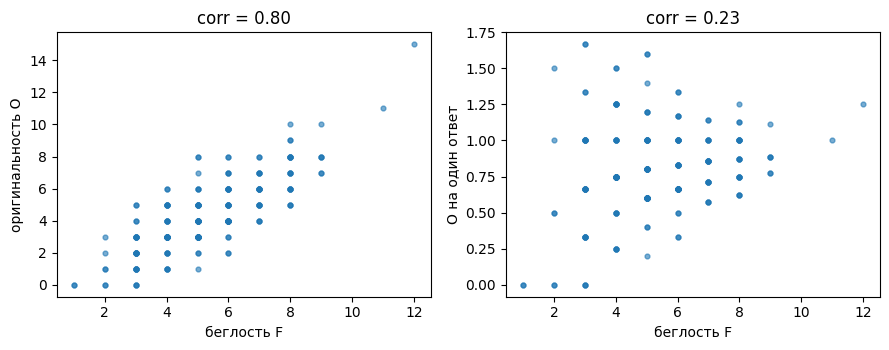

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True)
ax[0].scatter(F_big, O_big, s=12, alpha=0.6)        # (1)
ax[0].set_xlabel("беглость F")
ax[0].set_ylabel("оригинальность O")
ax[0].set_title(f"corr = {r_FO:.2f}")
ax[1].scatter(F_big, O_bar_big, s=12, alpha=0.6)
ax[1].set_xlabel("беглость F")
ax[1].set_ylabel("O на один ответ")
ax[1].set_title(f"corr = {r_FObar:.2f}")
fig.tight_layout()
fig.savefig("img/torrance_fluency_originality.png", dpi=150)  # (2)
plt.show()

**Разбор.**

**(1)** `scatter` рисует точку на испытуемого; `alpha=0.6` делает точки полупрозрачными, чтобы совпадающие значения были видны как более тёмные.

**(2)** Рисунок сохраняется в папку `img/` рядом с тетрадью — оттуда его берёт Markdown-версия урока.

Слева облако вытянуто вверх вправо: чем больше ответов, тем выше сумма баллов. Справа облако почти горизонтально.

### Шаг 11. Стандартизация: T-баллы

Сырой балл сам по себе не говорит, высокий он или низкий. Его переводят в шкалу со средним $\enfPar{50}$ и отклонением $\enfPar{10}$ относительно нормативной выборки:

$$
\enfTgt{T_i} = \enfPar{50} + \enfPar{10}\cdot\frac{\enfTgt{F_i} - \enfPar{\mu_F}}{\enfPar{\sigma_F}} .
$$

Это та же конструкция, что шкала IQ в лекции (слайд 13), только с другими константами.

In [14]:
def t_score(x: np.ndarray) -> np.ndarray:
    """T-балл относительно выборки: 50 + 10 z."""
    z = (x - x.mean()) / x.std(ddof=1)             # (1)
    return 50 + 10 * z                              # (2)


T_F = t_score(F_big)
print("mu_F =", round(F_big.mean(), 2),
      " sigma_F =", round(F_big.std(ddof=1), 2))
print("F:", F_big[:5], " T:", np.round(T_F[:5], 1))

mu_F = 5.3  sigma_F = 1.88
F: [7 4 6 3 7]  T: [59.  43.1 53.7 37.7 59. ]


**Таблица 8. T-балл: формула → код.**

| Формула | Python |
|---|---|
| $\enfPar{\mu_F}$ | `x.mean()` — среднее беглости по нормативной выборке |
| $\enfPar{\sigma_F}$ | `x.std(ddof=1)` — выборочное стандартное отклонение с делением на $\enfPar{N} - 1$ |
| $(\enfTgt{F_i} - \enfPar{\mu_F})/\enfPar{\sigma_F}$ | `(x - x.mean()) / x.std(ddof=1)` — вычисляется сразу для всего массива |
| $\enfPar{50} + \enfPar{10}\cdot(\ldots)$ | `50 + 10 * z` — сдвиг и растяжение шкалы |
| вся формула: $\enfTgt{T_i} = \enfPar{50} + \enfPar{10}\cdot(\enfTgt{F_i} - \enfPar{\mu_F})/\enfPar{\sigma_F}$ | `T_F = t_score(F_big)` |

**Разбор.**

**(1)** Операции с массивом NumPy выполняются поэлементно: `x - x.mean()` вычитает одно число из каждого элемента. `ddof=1` — поправка на число степеней свободы; без неё NumPy делит на $\enfPar{N}$.

**(2)** Результат — массив T-баллов той же длины.

T-балл, как и IQ, — место в распределении конкретной выборки: сменится выборка — сменятся $\enfPar{\mu_F}$, $\enfPar{\sigma_F}$ и сами T-баллы.

## Типичная ошибка: доля по ответам вместо доли по испытуемым

> [!warning] Деление на число ответов, а не на число людей
> Соблазнительно считать редкость ответа как долю среди **всех ответов** выборки. Знаменатель выходит в несколько раз больше $\enfPar{N}$, все доли резко падают, и почти любой ответ оказывается «редким». Ниже тот же расчёт с такой ошибкой.

In [15]:
total_answers = sum(len(S_i) for S_i in S.values())
p_wrong = {s: n[s] / total_answers for s in n}      # (1) ошибка
O_wrong = {i: sum(w(p_wrong[s]) for s in S_i) for i, S_i in S.items()}
print("всего ответов:", total_answers)
print("А: O =", O_wrong["А"], "  Б: O =", O_wrong["Б"])

всего ответов: 45
А: O = 15   Б: O = 12


**Разбор.**

**(1)** Знаменатель — число всех ответов выборки, а не число испытуемых $\enfPar{N}$. Доля «дома» падает с $\enfFun{0{,}9}$ до $\enfOp{9}/45 = \enfFun{0{,}2}$, доли остальных ответов А — ниже $\enfPar{\tau_1}$.

Итог ошибки: $\enfTgt{O_i}$ почти превращается в удвоенную беглость, и А с восемью строительными ответами обгоняет Б. Правильный знаменатель — число людей, потому что вопрос оригинальности звучит так: «какая часть испытуемых додумалась до этой идеи?»

## Упражнения

> [!question] Упражнение 1. Предскажите вывод
> Эксперт решил отнести «дорожку» к отдельной категории «благоустройство». Чему станет равна гибкость $\enfTgt{G_А}$? Ответьте до запуска, затем проверьте кодом.

> [!success]- Решение
> ```python
> category2 = dict(category, **{"дорожка": "благоустройство"})
> G_A2 = len({category2[s] for s in S["А"]})
> print("G_А =", G_A2)
> ```
> ```output
> G_А = 2
> ```
> `dict(category, **{...})` создаёт копию словаря с заменённым значением, исходный `category` не меняется. Гибкость зависит от экспертного решения о категориях: одна переклассификация удваивает $\enfTgt{G_А}$.

> [!question] Упражнение 2. Измените и объясните
> Пересчитайте $\enfTgt{O_А}$ и $\enfTgt{O_Б}$ при порогах $\enfPar{\tau_1} = \enfPar{0{,}2}$ и $\enfPar{\tau_2} = \enfPar{0{,}4}$. Почему изменилось отношение $\enfTgt{O_Б}/\enfTgt{O_А}$?

> [!success]- Решение
> ```python
> O2 = {i: sum(w(p[s], 0.2, 0.4) for s in S[i]) for i in ("А", "Б")}
> print(O2)
> ```
> ```output
> {'А': 11, 'Б': 11}
> ```
> С более мягкими порогами частые у А ответы с долей $\enfFun{0{,}2}$–$\enfFun{0{,}4}$ стали приносить больше баллов, и выигрыш беглости вырос: отношение $\enfTgt{O_Б}/\enfTgt{O_А}$ упало с $\enfTgt{9}/\enfTgt{6} = 1{,}5$ до $\enfTgt{11}/\enfTgt{11} = 1$: испытуемые сравнялись. Пороги $\enfPar{\tau_1}$, $\enfPar{\tau_2}$ — такие же параметры обработки, как уровень доверия в интервале для IQ, и их нужно называть.

> [!question] Упражнение 3. Найдите ошибку
> Коллега посчитал гибкость так: `G_bad = {i: len(set(S_i)) for i, S_i in S.items()}`. Что на самом деле вычисляет этот код?

> [!success]- Решение
> ```python
> G_bad = {i: len(set(S_i)) for i, S_i in S.items()}
> print(G_bad == F)
> ```
> ```output
> True
> ```
> `set(S_i)` — множество **ответов**, а не категорий, поэтому `len(set(S_i))` совпадает с беглостью $\enfTgt{F_i}$. Правило $\enfFun{c}$ в коде отсутствует: нет обращения к `category[s]`.

## Итоги

Беглость считает ответы, гибкость — категории, оригинальность — редкость ответов в конкретной выборке, разработанность — детали. Все четыре показателя опираются на решения, которые принимает не испытуемый, а обработчик: что считать адекватным, как делить на категории, какую выборку взять за норму, где поставить пороги. Суммарная оригинальность механически растёт с беглостью; оригинальность в расчёте на ответ эту связь снимает. Сравнение по выборке-эталону меняет вывод о том, кто оригинальнее.

| Математика | Python |
|---|---|
| $\enfTgt{F_i} = \lvert \enfVar{S_i} \rvert$ | `F = {i: len(S_i) for i, S_i in S.items()}` |
| $\enfTgt{G_i} = \bigl\lvert \{\enfFun{c}(\enfVar{s}) : \enfVar{s} \in \enfVar{S_i}\} \bigr\rvert$ | `len({category[s] for s in S_i})` |
| $\enfFun{p}(\enfVar{s}) = \enfOp{n}(\enfVar{s})/\enfPar{N}$ | `p = {s: n_s / N for s, n_s in n.items()}` |
| $\enfFun{w}(\enfVar{s})$ с порогами $\enfPar{\tau_1}$, $\enfPar{\tau_2}$ | `w(p_s, tau1=0.10, tau2=0.30)` |
| $\enfTgt{O_i} = \enfOp{\sum_{s \in S_i}} \enfFun{w}(\enfVar{s})$ | `sum(w(p[s]) for s in S_i)` |
| $\enfTgt{E_i} = \enfOp{\sum_{s \in S_i}} \enfVar{d_s}$ | `sum(S_i.values())` |
| $\enfTgt{T_i} = \enfPar{50} + \enfPar{10}\cdot(\enfTgt{F_i} - \enfPar{\mu_F})/\enfPar{\sigma_F}$ | `50 + 10 * (x - x.mean()) / x.std(ddof=1)` |

## Что дальше

- [Интеллектуальные способности, познавательная мотивация и творческие способности](Intellect_Motivation_Creativity.learning.md) — конспект лекции; этот урок иллюстрирует его слайды 31, 32 и 34.